Structure DC - PV Sendim
=
This notebook generates AutoCAD scripts for the DC side of PV Sendim. It draws the string cables (positive and negative), the DC trenches (valas) and the DC ducts (eletrodutos), routed from the strings on each structure line to their inverter.

**Workflow overview:**
1. Convert the DWG to DXF and load its entities into the `cad_entities` table of `pv_projects.duckdb` as project `"PV Sendim"`.
2. Select the string blocks and the inverter blocks. Plot them per PST to check the inverter assignment.
3. Decide whether each inverter is east or west of its strings.
4. Classify each string by structure type and position (`S`, `U_R` / `U_L`, `T` / `M` / `B`) and compute the structure line (`Line`) it sits on.
5. Split each structure line into `Group`s (continuous structure runs) and `SubGroup`s (the part of a run that goes to one inverter). Compute the structure ends and the string count of each SubGroup.
6. Map each string count to the ducts needed (max 3 strings per duct).
7. Classify each structure run and each string by its position relative to the inverter (8 cases), which picks one of 3 routing patterns.
8. Write `Script Cabos - Sendim.scr`, `Script Valas - Sendim.scr` and `Script Dutos - Sendim.scr`, plus Excel files on the Desktop for checking. A last cell plots one example cable per pattern.

**DWG prerequisites** (the code assumes all of these, and it doesn't check them):
- **File:** `PV Sendim - Eletromecânico 8.1.dwg` sits in `dwg_folder` (`C:\Users\Usuario\Desktop\projetos\sendim\eletromec`). The DXF is written to the same folder and deleted at the end. The ODA File Converter 27.1.0 must be installed at the path set in `DWG_to_DuckDB_ETL.py`. The converter converts every DWG in `temp_folder`, so keep only this drawing in it.
- **Database:** `load_to_duckdb` deletes every existing `"PV Sendim"` row in `cad_entities` before loading (the same project name is used by `Tagueamento Strings`, so each load replaces the other's data). `pv_projects.duckdb` is opened relative to the working directory.
- **Model space only:** strings and inverters are block references (`INSERT`) placed directly in model space.
- **Block names (case-sensitive):**
  - Strings: name `LIKE 'EMF302_string_%'` (in `LIKE`, `_` also matches any single character).
  - Inverters: exactly `EMF302_inversor`.
  - 2-string structure: the classification step recognises it only by the exact name `EMF422-1_string_2`. It has two blocks at the same point: rotation `0` = right half (`U_R`), any other rotation = left half (`U_L`).
  - Any other string block: blocks stacked at the same X (±0.5) and less than 5 apart in Y are `T` / `M` / `B`, and a block with no stacked neighbour is `S`.
- **Warning (Sendim):** the classification step checks the Reask block name `EMF422-1_string_2`, which doesn't exist here. So no string is ever `U_R` / `U_L`. Sendim's `EMF302_string_2` blocks (two stacked strings) become `T` / `B`, and `EMF302_string_1` becomes `S`.
  - The `T` / `B` line offset (±2.3204) and the exit offsets (5.193 / 11.053 / 16.913) come from the 3-high Reask structures.
  - With a 2-high stack, the `T` and `B` strings of one structure get different `Line`s (roughly each other's Y), so every structure is split into two lines / SubGroups (the saved output shows lines 156185 and 156182 for one structure). This halves the string counts and doubles the trenches and ducts.
  - `distance1` / `distance2` are also the Reask values.
- **Attributes:**
  - Inverter blocks carry `UFV`, `PST` and `INV`. The code rebuilds the inverter key as `UFV.PST.INV`, with `UFV` and `PST` used as they are and `INV` zero-padded to 2 digits, and the inverter's own `GRP` attribute is ignored.
  - Every string block carries `GRP` = its inverter key in exactly the same text format (e.g. `8.1.01`). Strings whose `GRP` doesn't match an inverter are dropped from the scripts.
- **Layout and geometry** (hardcoded values, tuned to the Reask structures):
  - Structure lines run east-west.
  - Stacked strings are about 2.32 apart (structure line = Y ∓ 2.3204 for `T` / `B`).
  - Structure ends are 5.193 (`S`), 11.053 (`U_R` / `U_L`) or 16.913 (`T` / `M` / `B`) from the block insertion point.
  - An X gap of more than 40 between consecutive strings on a line means a new structure run.
  - The inverters sit between structure lines: 6.6553 below the line above them (`distance1`) and 2 above the line below them (`distance2`).
- **When running the `.scr` in AutoCAD:**
  - The layers `EMF_cabo_solar_positivo`, `EMF_cabo_solar_negativo`, `EMF_DC_vala`, `EMF_bt_eletroduto_1S`, `EMF_bt_eletroduto_2S` and `EMF_bt_eletroduto_3S` must already exist (`LAYER S` doesn't create them).
  - The scripts set `PLINEWID` (0 for cables, 0.5 for trenches, 0.03 for ducts), and the value stays set after the script ends.
  - Turn off running object snaps (`OSMODE = 0`) so the script's points aren't snapped to nearby geometry.

Extracting the AutoCAD data and loading it into the duckdb database.
=

- Copies `PV Sendim - Eletromecânico 8.1.dwg` into `temp_folder`. `convert_dwg_to_dxf` runs the ODA File Converter on that folder and writes the DXF (ACAD2018) into `output_folder` (= `dwg_folder`).
- `load_to_duckdb` reads every model space entity with `ezdxf` and loads it into `cad_entities` as `"PV Sendim"`. It deletes the project's old rows first. For blocks it stores the name, insertion point (`X`, `Y`), rotation, color and the attribute tags (`UFV`, `PST`, `INV`, `STR`, `GRP`, ...).
- The DXF and the temporary DWG are deleted. The connection `conn` stays open and is closed at the end of the script-writing step.

In [29]:
from DWG_to_DuckDB_ETL import *
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


dwg_folder = r"C:\Users\Usuario\Desktop\projetos\sendim\eletromec"
temp_folder = r"C:\Users\Usuario\Desktop\projetos\sendim\eletromec\temp"
output_folder = dwg_folder

os.makedirs(temp_folder, exist_ok=True)
dwg_file = os.path.join(dwg_folder, "PV Sendim - Eletromecânico 8.1.dwg")

shutil.copy(dwg_file, temp_folder)

convert_dwg_to_dxf(temp_folder, output_folder)

dxf_file = os.path.join(output_folder, "PV Sendim - Eletromecânico 8.1.dxf")

temp_dwg_file = os.path.join(temp_folder, "PV Sendim - Eletromecânico 8.1.dwg")

conn = load_to_duckdb(dxf_file, "PV Sendim")
print("Data Loaded")
print("DuckDB Loaded")

os.remove(dxf_file)
os.remove(temp_dwg_file)

Project PV Sendim already exists
Removed existing data for project: PV Sendim
Successfully loaded project
Loaded 134 entities for project: PV Sendim
Don't forget to close connection.
Data Loaded
DuckDB Loaded


Loading the data from PV Sendim
=

- `data_ELM` = relation with `layer`, `name`, `X`, `Y`, `UFV`, `PST`, `INV`, `GRP`, `STR` and `rotation` for `PV Sendim`. The next cells query it by its Python variable name.
- Layer count on `data_ELM` (this project only), for information. It helps spot blocks on unexpected layers.

In [30]:
data_ELM = conn.sql("SELECT layer, name, X, Y, UFV, PST, INV, GRP, STR, rotation FROM cad_entities WHERE project_name = 'PV Sendim'")

print(data_ELM)

result = conn.sql("""
    SELECT
        layer,
        COUNT(*) as count
    FROM data_ELM
    GROUP BY layer
    ORDER BY count
""")

print(result)

┌────────────────────────┬───────────────────┬───────────┬────────────┬─────────┬─────────┬─────────┬─────────┬─────────┬──────────┐
│         layer          │       name        │     X     │     Y      │   UFV   │   PST   │   INV   │   GRP   │   STR   │ rotation │
│        varchar         │      varchar      │   float   │   float    │ varchar │ varchar │ varchar │ varchar │ varchar │  float   │
├────────────────────────┼───────────────────┼───────────┼────────────┼─────────┼─────────┼─────────┼─────────┼─────────┼──────────┤
│ 0                      │ PV Sendim - Civil │       0.0 │        0.0 │ NULL    │ NULL    │ NULL    │ NULL    │ NULL    │      0.0 │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor   │ 49897.566 │  156170.11 │ 8       │ 1       │ 1       │ 8.1.01  │ NULL    │      0.0 │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor   │ 49914.875 │  156125.11 │ 8       │ 1       │ 4       │ 8.1.04  │ NULL    │      0.0 │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor   │  49912.23 │  156117.61

Separating the data into different dataframes.
=
First one is for strings.

- Selects the string blocks (`name LIKE 'EMF302_string_%'`) from `data_ELM` into `strings_df` (126 strings in the saved output) and prints a summary.
- One row per string, with `X`, `Y`, `rotation` and the `UFV`, `PST`, `INV`, `GRP`, `STR` attributes.
- `inv_order` = sorted list of the `INV` values. It fixes the legend / color order of the plots.
- The commented-out lines are a single-PST version of the plot in the next cell.

In [31]:
strings = conn.sql("SELECT * FROM data_ELM WHERE name LIKE 'EMF302_string_%'")

strings_df = strings.fetchdf()
print(strings)
print(strings_df.describe())
print(strings_df.info())

inv_order = sorted(strings_df['INV'].unique())

# ax = sns.scatterplot(data=strings_df[strings_df['PST']=='01'], x="X", y="Y", hue="INV", style='name', hue_order=inv_order, palette='Set1')
# sns.move_legend(ax,'upper left', bbox_to_anchor=(1, 1))
# plt.show()

┌────────────────────────┬─────────────────┬───────────┬───────────┬─────────┬─────────┬─────────┬─────────┬─────────┬──────────┐
│         layer          │      name       │     X     │     Y     │   UFV   │   PST   │   INV   │   GRP   │   STR   │ rotation │
│        varchar         │     varchar     │   float   │   float   │ varchar │ varchar │ varchar │ varchar │ varchar │  float   │
├────────────────────────┼─────────────────┼───────────┼───────────┼─────────┼─────────┼─────────┼─────────┼─────────┼──────────┤
│ EMF_em_ufv_Sendim_08.1 │ EMF302_string_2 │ 49830.758 │ 156184.52 │ 8       │ 1       │ 1       │ 8.1.01  │ 4       │      0.0 │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_string_2 │ 49830.758 │ 156182.19 │ 8       │ 1       │ 1       │ 8.1.01  │ 5       │      0.0 │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_string_2 │  49870.45 │ 156184.52 │ 8       │ 1       │ 1       │ 8.1.01  │ 6       │      0.0 │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_string_2 │  49870.45 │ 156182.19 │ 8       │ 1       │ 1

Plot: strings per PST
=
Visual check of the string-to-inverter assignment: one scatter plot per `PST`, colored by `INV` and marked by block name. The axes aren't shared, and the aspect ratio is equal.

Saved as `pst_plots.pdf` on the Desktop (hardcoded path, overwritten each run).

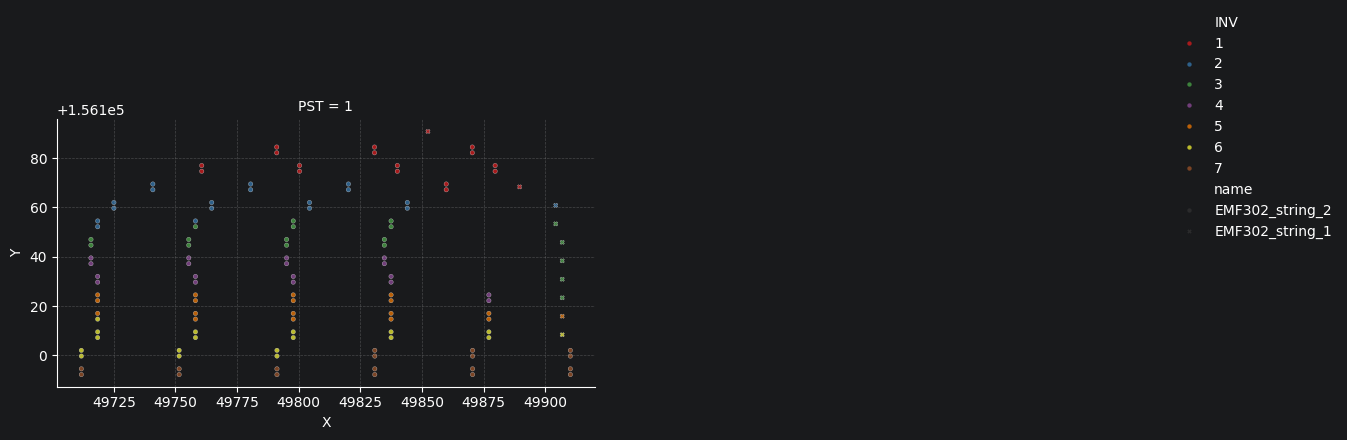

In [32]:
g = sns.relplot(
    data=strings_df, x="X", y="Y",
    col='PST', hue="INV", style='name',
    kind='scatter',
    col_wrap=2,
    height=5,
    aspect=1,
    s=10,
    alpha=0.7,
    facet_kws={'sharex': False, 'sharey': False},
    palette='Set1',
    hue_order=inv_order
)

# Move legend outside
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

# Apply equal aspect and grid to all subplots
for ax in g.axes.flat:
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()
g.figure.savefig(r"C:\Users\Usuario\Desktop\pst_plots.pdf", dpi=300, bbox_inches='tight')

Second one is for the inverters.

- Selects the inverter blocks by exact name `EMF302_inversor`.
- `GRP` is rebuilt as `UFV.PST.INV`, with `INV` zero-padded to 2 digits (`8.1.01`). The `UFV` / `PST` text must match the strings' `GRP` exactly (here `8` and `1`, not zero-padded).
- Renames `X` / `Y` to `inverter_x` / `inverter_y`.
- The last line draws a quick scatter of all inverters colored by `PST`.

┌────────────────────────┬─────────────────┬───────────┬────────────┬─────────┬─────────┬─────────┬─────────┐
│         layer          │      name       │     X     │     Y      │   UFV   │   PST   │   INV   │   GRP   │
│        varchar         │     varchar     │   float   │   float    │ varchar │ varchar │ varchar │ varchar │
├────────────────────────┼─────────────────┼───────────┼────────────┼─────────┼─────────┼─────────┼─────────┤
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor │ 49897.566 │  156170.11 │ 8       │ 1       │ 1       │ 8.1.01  │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor │ 49914.875 │  156125.11 │ 8       │ 1       │ 4       │ 8.1.04  │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor │  49912.23 │  156117.61 │ 8       │ 1       │ 5       │ 8.1.05  │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor │ 49928.098 │  156102.61 │ 8       │ 1       │ 6       │ 8.1.06  │
│ EMF_em_ufv_Sendim_08.1 │ EMF302_inversor │  49925.47 │  156095.11 │ 8       │ 1       │ 7       │ 8.1.07  │
│ EMF_em_u

<Axes: xlabel='inverter_x', ylabel='inverter_y'>

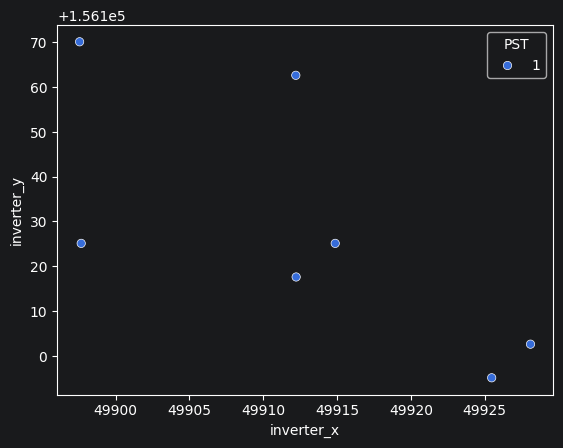

In [33]:
inverter = conn.sql("SELECT layer, name, X, Y, UFV, PST, INV, GRP FROM data_ELM WHERE name = 'EMF302_inversor'")
print(inverter)

inverter_df = inverter.fetchdf()
inverter_df["UFV"] = inverter_df["UFV"].astype(str)
inverter_df['GRP'] = inverter_df["UFV"].astype(str) + "." + inverter_df["PST"].astype(str) + "." + inverter_df["INV"].astype(str).str.zfill(2)
inverter_df.rename(columns={'X': 'inverter_x', 'Y': 'inverter_y'}, inplace=True)

print(inverter_df.describe())
print(inverter_df.info())
print(inverter_df)
sns.scatterplot(inverter_df, x='inverter_x', y='inverter_y', hue='PST', style='PST')

Plot: inverters per PST
=
Same layout as the string plot: one scatter per `PST`, colored by `INV`, using the same `inv_order`. Saved as `inv_plots.pdf` on the Desktop (hardcoded path).

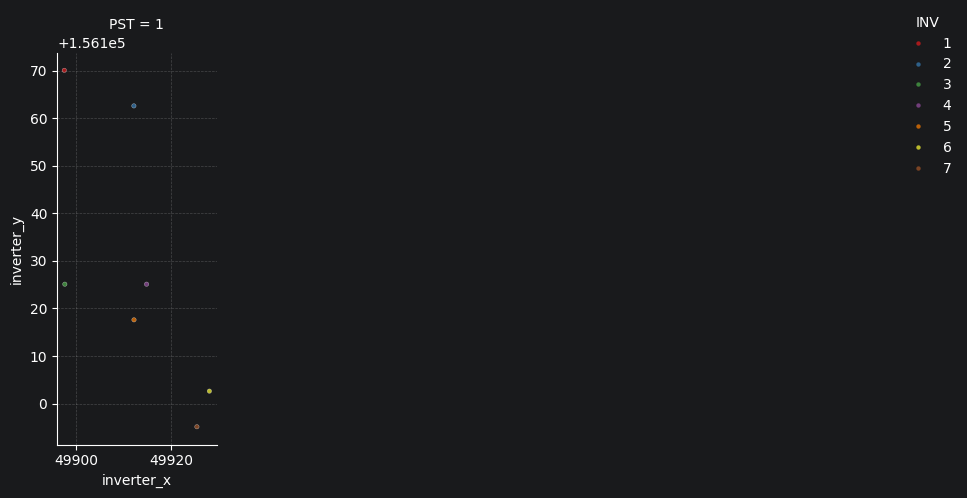

In [34]:
g = sns.relplot(
    data=inverter_df, x="inverter_x", y="inverter_y",
    col='PST', hue="INV",
    kind='scatter',
    col_wrap=2,
    height=5,
    aspect=1,
    s=10,
    alpha=0.7,
    facet_kws={'sharex': False, 'sharey': False},
    palette='Set1',
    hue_order=inv_order
)

# Move legend outside
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

# Apply equal aspect and grid to all subplots
for ax in g.axes.flat:
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()
g.figure.savefig(r"C:\Users\Usuario\Desktop\inv_plots.pdf", dpi=300, bbox_inches='tight')

Comparing the coordinates of the inverter to the mean of the X coordinate from all the strings that share a GRP with the inverter to determine whether is the inverter is to the west (W) or east (E) in relation to their strings.
=

- `Comparing X` = the mean X of all strings with the same `GRP`, i.e. the centre of the inverter's string field.
- Inner merge with `inverter_df` on `GRP`. The two printed lengths (`1:` / `2:`) show whether strings were lost: here 126 → 126, so every string found its inverter.
- `INVERTER - E or W` = `E` if `inverter_x` ≥ `Comparing X`, otherwise `W`.
- `inverter_position` keeps one row per `GRP`. It is used later by the relative position function.

In [35]:
struct_df = strings_df.copy()
struct_df['Comparing X'] = struct_df.groupby('GRP')['X'].transform('mean')
print(f'1:{len(struct_df)}')
struct_df = struct_df.merge(inverter_df, on='GRP')
print(f'2:{len(struct_df)}')
struct_df['INVERTER - E or W'] = np.where(
    struct_df['inverter_x'] >= struct_df['Comparing X'],
    'E',
    'W'
)
inverter_position = struct_df[['GRP', 'INVERTER - E or W']].drop_duplicates("GRP").sort_values(by='GRP').reset_index(drop=True)
print(inverter_position)

1:126
2:126
      GRP INVERTER - E or W
0  8.1.01                 E
1  8.1.02                 E
2  8.1.03                 E
3  8.1.04                 E
4  8.1.05                 E
5  8.1.06                 E
6  8.1.07                 E


Iterating through the strings dataframe to determine the classification of each string.
=

S = 1-string structure.

U_R = Middle part of structure on the right on a 2-string structure.
U_L = Middle part of structure on the left on a 2-string structure.

T = Top string of a 3-string structure.
M = Middle string of a 3-string structure.
B = Bottom string of a 3-string structure.

- For each string, it looks for stacked neighbours: other strings less than 0.5 away in X and 5 in Y, with a different Y.
- `EMF422-1_string_2` is checked first: rotation `0` → `U_R`, otherwise `U_L`.
- Any other block with neighbours: above all of them → `T`, above some → `M`, below all → `B`. Without neighbours → `S`.
- `Line` = the Y of the structure centre, rounded to an integer: `S`, `U_R`, `U_L` and `M` → Y, `T` → Y − 2.3204, `B` → Y + 2.3204.
- Sorts by `Line` descending (north to south), then X ascending (west to east). The break conditions in the next step depend on this order.
- The loop runs row by row (`iterrows`) and compares against every string, so it gets slow on large plants.
- `value_counts()`: on complete 3-high structures, the `T`, `M` and `B` counts are equal, and so are the `U_R` and `U_L` counts.
- **Sendim:** the `EMF422-1_string_2` check never matches here, and the ±2.3204 offset splits each 2-high structure into two lines (see the warning at the top of the notebook).

In [36]:
for idx, row in strings_df.iterrows():
    x = row['X']
    y = row['Y']


    mask_TMB = (
        (strings_df['Y'] >= y - 5) &
        (strings_df['Y'] <= y + 5) &
        (strings_df['X'] >= x - 0.5) &
        (strings_df['X'] <= x + 0.5) &
        (strings_df['Y'] != y) &
        (strings_df.index != idx)
    )

    if row['name'] == 'EMF422-1_string_2':
        if row['rotation'] == 0:
            strings_df.loc[idx, 'Type'] = "U_R"
        else:
            strings_df.loc[idx, 'Type'] = "U_L"

    elif mask_TMB.any():
        y_neighbors = strings_df.loc[mask_TMB, 'Y']

        if (y > y_neighbors).all():
            strings_df.loc[idx, 'Type'] = "T"
        elif (y > y_neighbors).any():
            strings_df.loc[idx, 'Type'] = "M"
        else:
            strings_df.loc[idx, 'Type'] = "B"

    else:
        strings_df.loc[idx, 'Type'] = "S"


strings_df.loc[:,'Line'] = np.where(
    (strings_df["Type"] == "S") | (strings_df["Type"] == "U_R") | (strings_df["Type"] == "U_L") | (strings_df["Type"] == "M"),
    round(strings_df["Y"]),
    np.where(
        strings_df["Type"] == "T",
        round(strings_df["Y"] - 2.3204),
        round(strings_df["Y"] + 2.3204)
    )
)


strings_df.sort_values(by=["Line", "X"], ascending=[False,True], inplace=True, ignore_index=True)
print(strings_df)
print(strings_df['Type'].value_counts())

                      layer             name             X              Y UFV  \
0    EMF_em_ufv_Sendim_08.1  EMF302_string_1  49852.445312  156190.843750   8   
1    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.070312  156182.187500   8   
2    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49830.757812  156182.187500   8   
3    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49870.449219  156182.187500   8   
4    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.070312  156184.515625   8   
..                      ...              ...           ...            ...  ..   
121  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49751.484375  156094.515625   8   
122  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.175781  156094.515625   8   
123  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49830.867188  156094.515625   8   
124  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49870.554688  156094.515625   8   
125  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49910.246094  156094.515625   8   

    PST INV     GRP STR  ro

Conditions to break the strings into groups and subgroups.
=

Each row is compared with the previous one (in the sort order above):
- `condition1`: the `Line` changes.
- `condition2`: the X gap to the previous string is more than 40 (the structure run is interrupted).
- `condition3`: the `GRP` (inverter key) changes. The comment says "Different PSTs", but it compares the full inverter key.

`Group` = cumulative sum of conditions 1 and 2, i.e. one continuous structure run. `SubGroup` also breaks on condition 3, so it is the part of a run that goes to one inverter.

In [37]:
#Different Lines
condition1 = strings_df["Line"] != strings_df["Line"].shift()

#Break in the Structure
condition2 = abs(strings_df["X"] - strings_df["X"].shift()) > 40

#Different PSTs
condition3 = strings_df["GRP"] != strings_df["GRP"].shift()



break_condition_1 = condition1 | condition2 | condition3
break_condition_2 = condition1 | condition2

strings_df['SubGroup'] = break_condition_1.cumsum()
strings_df['Group'] = break_condition_2.cumsum()
print(strings_df)

                      layer             name             X              Y UFV  \
0    EMF_em_ufv_Sendim_08.1  EMF302_string_1  49852.445312  156190.843750   8   
1    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.070312  156182.187500   8   
2    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49830.757812  156182.187500   8   
3    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49870.449219  156182.187500   8   
4    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.070312  156184.515625   8   
..                      ...              ...           ...            ...  ..   
121  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49751.484375  156094.515625   8   
122  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.175781  156094.515625   8   
123  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49830.867188  156094.515625   8   
124  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49870.554688  156094.515625   8   
125  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49910.246094  156094.515625   8   

    PST INV     GRP STR  ro

W exit means the west-most exit of the structure line.
E exit means the east-most exit of the structure line.

Also creates the Dataframe for the cable generation.

- `W exit` / `E exit` per string = X ∓ 5.193 (`S`), ∓ 11.053 (`U_R` / `U_L`, both halves share the insertion point), ∓ 16.913 (`T` / `M` / `B`). These are half the structure lengths, measured from the block insertion point.
- `SubGroup - Position X - W/E` and `Group - Position X - W/E` = the minimum `W exit` / maximum `E exit` of each SubGroup / Group.
- `cables_df` = `strings_df` inner-merged with `inverter_df` on `GRP`: one row per string, with its inverter coordinates. Strings without an inverter are dropped. The duplicated columns get `_x` / `_y` suffixes and are dropped in the cable routing step. It is built before `No. of Strings`, so it doesn't have that column.
- `No. of Strings` = the number of strings in each SubGroup. The printed `value_counts()` counts strings, not SubGroups, and its sum is the total number of strings.

In [38]:
strings_df['W exit'] = np.where(
    strings_df["Type"] == "S",
    strings_df['X'] - 5.193,
    np.where(
        (strings_df["Type"] == "U_R") | (strings_df["Type"] == "U_L"),
        strings_df['X'] - 11.053,
        strings_df['X'] - 16.913
    )
)

strings_df['E exit'] = np.where(
    strings_df["Type"] == "S",
    strings_df['X'] + 5.193,
    np.where(
        (strings_df["Type"] == "U_R") | (strings_df["Type"] == "U_L"),
        strings_df['X'] + 11.053,
        strings_df['X'] + 16.913
    )
)

strings_df['SubGroup - Position X - W'] = strings_df.groupby("SubGroup")["W exit"].transform('min')
strings_df['SubGroup - Position X - E'] = strings_df.groupby("SubGroup")["E exit"].transform('max')

strings_df['Group - Position X - W'] = strings_df.groupby("Group")["W exit"].transform('min')
strings_df['Group - Position X - E'] = strings_df.groupby("Group")["E exit"].transform('max')

cables_df = strings_df.merge(inverter_df, on="GRP")

strings_df['No. of Strings'] = strings_df.groupby("SubGroup")['name'].transform('count')

print(strings_df)
print(strings_df['No. of Strings'].value_counts())
print(strings_df['No. of Strings'].value_counts().sum())

                      layer             name             X              Y UFV  \
0    EMF_em_ufv_Sendim_08.1  EMF302_string_1  49852.445312  156190.843750   8   
1    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.070312  156182.187500   8   
2    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49830.757812  156182.187500   8   
3    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49870.449219  156182.187500   8   
4    EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.070312  156184.515625   8   
..                      ...              ...           ...            ...  ..   
121  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49751.484375  156094.515625   8   
122  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49791.175781  156094.515625   8   
123  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49830.867188  156094.515625   8   
124  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49870.554688  156094.515625   8   
125  EMF_em_ufv_Sendim_08.1  EMF302_string_2  49910.246094  156094.515625   8   

    PST INV     GRP STR  ro

Grouping the data per Subgroup

- One row per SubGroup with `groupby("SubGroup").first()`. The positions and counts are the same for every row of a SubGroup.
- Renames: `Line` → `Y`, SubGroup ends → `X-W-STR` / `X-E-STR`, Group (structure run) ends → `X-W-STRUCT` / `X-E-STRUCT`.
- Prints the maximum number of strings in a SubGroup. It must be covered by `duct_map` in the next step (6 here).

In [39]:
groups_df = strings_df.groupby("SubGroup")[['GRP', 'Line', 'SubGroup - Position X - W', 'SubGroup - Position X - E', 'Group - Position X - W', 'Group - Position X - E', 'No. of Strings']].first()
groups_df.rename(columns={'Line': 'Y', 'Group - Position X - W': 'X-W-STRUCT', 'Group - Position X - E': 'X-E-STRUCT', 'SubGroup - Position X - W': 'X-W-STR', 'SubGroup - Position X - E': 'X-E-STR'}, inplace=True)
print(f'Maximum number of strings in a group: {groups_df['No. of Strings'].max()}\n')
print(groups_df)

Maximum number of strings in a group: 6

             GRP         Y       X-W-STR       X-E-STR    X-W-STRUCT  \
SubGroup                                                               
1         8.1.01  156191.0  49847.253906  49857.636719  49847.253906   
2         8.1.01  156185.0  49774.156250  49887.363281  49774.156250   
3         8.1.01  156182.0  49774.156250  49887.363281  49774.156250   
4         8.1.01  156177.0  49743.730469  49896.628906  49743.730469   
5         8.1.01  156175.0  49743.730469  49896.628906  49743.730469   
6         8.1.02  156170.0  49723.886719  49837.093750  49723.886719   
7         8.1.01  156170.0  49842.957031  49876.785156  49723.886719   
8         8.1.01  156168.0  49884.445312  49894.828125  49884.445312   
9         8.1.02  156167.0  49723.886719  49837.093750  49723.886719   
10        8.1.01  156167.0  49842.957031  49876.785156  49723.886719   
11        8.1.02  156162.0  49708.089844  49860.988281  49708.089844   
12        8.1.02  15616

Duct_map is needed to represent how many ducts are necessary and how many strings are there in each duct. Given that the maximum of strings in a duct is 3, the duct_map is as follows:
=

- The key is `No. of Strings`, and the value lists the strings per duct between dashes (`-3-3-1-` = three ducts with 3, 3 and 1 strings).
- `Number of Ducts` = number of dashes − 1 (for information only; the scripts don't use it).
- A count above 22 isn't in the map and becomes `NaN` (`Number of Ducts` = −1 and no duct lines). Extend the map if the maximum printed above grows.
- Merges with `inverter_df` on `GRP` (inner join). SubGroups without an inverter are dropped without warning.
- `W or E` = which end of the whole structure run (`X-W-STRUCT` / `X-E-STRUCT`) is closer to the inverter, and `closest_x` = the X of that end. The trench and ducts leave the structure line there.

In [40]:
duct_map = {
    1: '-1-',
    2: '-2-',
    3: '-3-',
    4: '-3-1-',
    5: '-3-2-',
    6: '-3-3-',
    7: '-3-3-1-',
    8: '-3-3-2-',
    9: '-3-3-3-',
    10: '-3-3-3-1-',
    11: '-3-3-3-2-',
    12: '-3-3-3-3-',
    13: '-3-3-3-3-1-',
    14: '-3-3-3-3-2-',
    15: '-3-3-3-3-3-',
    16: '-3-3-3-3-3-1-',
    17: '-3-3-3-3-3-2-',
    18: '-3-3-3-3-3-3-',
    19: '-3-3-3-3-3-3-1-',
    20: '-3-3-3-3-3-3-2-',
    21: '-3-3-3-3-3-3-3-',
    22: '-3-3-3-3-3-3-3-1-',
}

groups_df.loc[:,'Duct Definition'] = groups_df['No. of Strings'].map(duct_map)
groups_df['Number of Ducts'] = groups_df['Duct Definition'].astype(str).str.count('-')-1
groups_df = groups_df.merge(inverter_df, on='GRP')
groups_df['W or E'] = np.where(
    abs(groups_df['X-W-STRUCT'] - groups_df['inverter_x']) > abs(groups_df['X-E-STRUCT'] - groups_df['inverter_x']),
    "E",
    "W"
)

groups_df['closest_x'] = np.where(
    groups_df['W or E'] == "W",
    groups_df['X-W-STRUCT'],
    groups_df['X-E-STRUCT']
)

print(groups_df)

       GRP         Y       X-W-STR       X-E-STR    X-W-STRUCT    X-E-STRUCT  \
0   8.1.01  156191.0  49847.253906  49857.636719  49847.253906  49857.636719   
1   8.1.01  156185.0  49774.156250  49887.363281  49774.156250  49887.363281   
2   8.1.01  156182.0  49774.156250  49887.363281  49774.156250  49887.363281   
3   8.1.01  156177.0  49743.730469  49896.628906  49743.730469  49896.628906   
4   8.1.01  156175.0  49743.730469  49896.628906  49743.730469  49896.628906   
5   8.1.02  156170.0  49723.886719  49837.093750  49723.886719  49876.785156   
6   8.1.01  156170.0  49842.957031  49876.785156  49723.886719  49876.785156   
7   8.1.01  156168.0  49884.445312  49894.828125  49884.445312  49894.828125   
8   8.1.02  156167.0  49723.886719  49837.093750  49723.886719  49876.785156   
9   8.1.01  156167.0  49842.957031  49876.785156  49723.886719  49876.785156   
10  8.1.02  156162.0  49708.089844  49860.988281  49708.089844  49860.988281   
11  8.1.02  156161.0  49899.089844  4990

Cables: per-string routing data
=
- Drops the duplicated merge columns (`*_x` / `*_y`) and `SubGroup` / `Group`, and renames the position columns like in `groups_df`.
- `W or E or M`: `E` if the string's `E exit` is closer to the inverter than its `W exit`, otherwise `W`. The `M` branch (inverter between the two exits) can never be true: it needs `inverter_x` < `W exit` and > `E exit` at the same time, while `W exit` < `E exit`.
- `closest_x` = the end of the structure run closest to the inverter. This is the "pile" point where the cable leaves the structure line, the same point the trench uses.
- `Exit` = the string's own end where the cable starts (`E exit` if `E`, otherwise `W exit`).
- Sorted by `GRP` and `Line`.

In [41]:
cables_df.drop(columns=['UFV_x', 'UFV_y', 'PST_x', 'PST_y', 'INV_x', 'INV_y', 'SubGroup', 'Group', 'layer_x', 'name_x', 'layer_y', 'name_y'], inplace=True)
cables_df.rename(columns={'Group - Position X - W': 'X-W-STRUCT', 'Group - Position X - E': 'X-E-STRUCT', 'SubGroup - Position X - W': 'X-W-STR', 'SubGroup - Position X - E': 'X-E-STR'}, inplace=True)
cables_df['W or E or M'] = np.where(
    abs(cables_df['W exit'] - cables_df['inverter_x']) > abs(cables_df['E exit'] - cables_df['inverter_x']),
    "E",
    np.where(
        (cables_df['inverter_x'] < cables_df['W exit']) & (cables_df['inverter_x'] > cables_df['E exit']),
        "M",
        "W"
    )
)

# THIS FINDS THE CLOSEST X TO EXIT THE STRING.
# CALCULATING WHICH ONE IS THE CLOSEST ONE (X-W-STRUCT, X-E-STRUCT).
cables_df['closest_x'] = np.where(
    abs(cables_df['X-W-STRUCT'] - cables_df['inverter_x']) < abs(cables_df['X-E-STRUCT'] - cables_df['inverter_x']),
    cables_df['X-W-STRUCT'],
    cables_df['X-E-STRUCT']
)

cables_df['Exit'] = np.where(
    cables_df['W or E or M'] == 'E',
    cables_df['E exit'],
    cables_df['W exit']
)

cables_df.sort_values(['GRP', 'Line'], inplace = True)
print(cables_df.head())

               X              Y     GRP STR  rotation Type      Line  \
23  49859.871094  156169.515625  8.1.01  16       0.0    T  156167.0   
19  49889.636719  156168.359375  8.1.01  18       0.0    S  156168.0   
18  49859.871094  156167.187500  8.1.01  17       0.0    B  156170.0   
11  49760.644531  156177.015625  8.1.01   8       0.0    T  156175.0   
12  49800.335938  156177.015625  8.1.01  10       0.0    T  156175.0   

          W exit        E exit       X-W-STR       X-E-STR    X-W-STRUCT  \
23  49842.957031  49876.785156  49842.957031  49876.785156  49723.886719   
19  49884.445312  49894.828125  49884.445312  49894.828125  49884.445312   
18  49842.957031  49876.785156  49842.957031  49876.785156  49723.886719   
11  49743.730469  49777.558594  49743.730469  49896.628906  49743.730469   
12  49783.421875  49817.250000  49743.730469  49896.628906  49743.730469   

      X-E-STRUCT    inverter_x     inverter_y W or E or M     closest_x  \
23  49876.785156  49897.566406  156

Position relative to the inverter
=
`position_of_structure_regarding_inverter` merges `inverter_position` (inner join on `GRP`) and puts each row in one of 8 cases, coded `R/L_A/B_E/W`:
- `R` / `L`: `closest_x` is right / left of `inverter_x` (equal counts as `L`).
- `A` / `B`: `Y` is above / below `inverter_y` (equal counts as `B`). In `cables_df`, `Y` is the string Y. In `groups_df`, it is the structure line.
- `E` / `W`: the inverter is east / west of its strings (from the E or W step).

The 8 conditions cover every case, so the `'unk'` default never shows up.

Exports `cables.xlsx` and `groups.xlsx` to the Desktop for checking (hardcoded paths). `cables.xlsx` is overwritten again in the next step.

In [42]:
# print(cables_df.columns)
# print(groups_df.columns)
def position_of_structure_regarding_inverter(df):
    """
    The function takes a Dataframe and defines where the line of structure or the string is regarding their inverter.
    Option 1: Right (R)(X coordinate) and above (A)(Y coordinate) the inverter. Inverter east of the GRP (E). Being set as "R_A_E"; or
    Option 2: Right (R)(X coordinate) and below (B)(Y coordinate) the inverter. Inverter east of the GRP (E). Being set as "R_B_E"; or
    Option 3: Left (L)(X coordinate) and above (A)(Y coordinate) the inverter. Inverter east of the GRP (E). Being set as "L_A_E"; or
    Option 4: Left (L)(X coordinate) and below (B)(Y coordinate) the inverter. Inverter east of the GRP (E). Being set as "L_B_E"; or
    Option 5: Right (R)(X coordinate) and above (A)(Y coordinate) the inverter. Inverter west of the GRP (W). Being set as "R_A_W"; or
    Option 6: Right (R)(X coordinate) and below (B)(Y coordinate) the inverter. Inverter west of the GRP (W). Being set as "R_B_W"; or
    Option 7: Left (L)(X coordinate) and above (A)(Y coordinate) the inverter. Inverter west of the GRP (W). Being set as "L_A_W"; or
    Option 8: Left (L)(X coordinate) and below (B)(Y coordinate) the inverter. Inverter west of the GRP (W). Being set as "L_B_W".
    """
    df = df.merge(inverter_position, on='GRP')

    inverter_east = df['INVERTER - E or W'] == 'E'
    inverter_west = ~inverter_east

    right_of_inverter = df['closest_x'] - df['inverter_x'] > 0
    left_of_inverter = ~right_of_inverter

    above_inverter = df['Y'] - df['inverter_y'] > 0
    below_inverter = ~above_inverter

    conditions = [
        # East cases
        inverter_east & right_of_inverter & above_inverter,
        inverter_east & right_of_inverter & below_inverter,
        inverter_east & left_of_inverter & above_inverter,
        inverter_east & left_of_inverter & below_inverter,

        # West cases
        inverter_west & right_of_inverter & above_inverter,
        inverter_west & right_of_inverter & below_inverter,
        inverter_west & left_of_inverter & above_inverter,
        inverter_west & left_of_inverter & below_inverter,
    ]

    choices = ['R_A_E', 'R_B_E', 'L_A_E', 'L_B_E', 'R_A_W', 'R_B_W', 'L_A_W', 'L_B_W']


    df['Relative_Position'] = np.select(conditions, choices, default='unk')

    return df

cables_df = position_of_structure_regarding_inverter(cables_df)
groups_df = position_of_structure_regarding_inverter(groups_df)
cables_df.to_excel(r"C:\Users\Usuario\Desktop\cables.xlsx")
groups_df.to_excel(r"C:\Users\Usuario\Desktop\groups.xlsx")

Displays `groups_df` (after the relative position step, so it includes `Relative_Position`) for a visual check.

In [43]:
groups_df

,GRP,Y,X-W-STR,X-E-STR,X-W-STRUCT,X-E-STRUCT,No. of Strings,Duct Definition,Number of Ducts,layer,name,inverter_x,inverter_y,UFV,PST,INV,W or E,closest_x,INVERTER - E or W,Relative_Position
0,8.1.01,156191.0,49847.253906,49857.636719,49847.253906,49857.636719,1,-1-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49857.636719,E,L_A_E
1,8.1.01,156185.0,49774.156250,49887.363281,49774.156250,49887.363281,3,-3-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49887.363281,E,L_A_E
2,8.1.01,156182.0,49774.156250,49887.363281,49774.156250,49887.363281,3,-3-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49887.363281,E,L_A_E
3,8.1.01,156177.0,49743.730469,49896.628906,49743.730469,49896.628906,4,-3-1-,2,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49896.628906,E,L_A_E
4,8.1.01,156175.0,49743.730469,49896.628906,49743.730469,49896.628906,4,-3-1-,2,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49896.628906,E,L_A_E
5,8.1.02,156170.0,49723.886719,49837.093750,49723.886719,49876.785156,3,-3-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49912.207031,156162.625000,8,1,2,E,49876.785156,E,L_A_E
6,8.1.01,156170.0,49842.957031,49876.785156,49723.886719,49876.785156,1,-1-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49876.785156,E,L_B_E
7,8.1.01,156168.0,49884.445312,49894.828125,49884.445312,49894.828125,1,-1-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49894.828125,E,L_B_E
8,8.1.02,156167.0,49723.886719,49837.093750,49723.886719,49876.785156,3,-3-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49912.207031,156162.625000,8,1,2,E,49876.785156,E,L_A_E
9,8.1.01,156167.0,49842.957031,49876.785156,49723.886719,49876.785156,1,-1-,1,EMF_em_ufv_Sendim_08.1,EMF302_inversor,49897.566406,156170.109375,8,1,1,E,49876.785156,E,L_B_E


Writing the cable, trench and duct scripts
=
- `intermediary_coordinates` adds three points 1.7, 1.5 and 1.3 from the inverter, on the structure side, and moves `inverter_y` 0.1 toward the structure (in place). It runs on `cables_df` (relative to the string Y) and on `script_df` (relative to the structure line). The extra vertices make the polylines easier to stretch later.
- `make_pline(row, is_cable, offset)` builds one `_.pline` line:
  - Cables start at `(Exit, Line)` (the string end on the structure line).
  - Then `(closest_x, Line)`, the pile point at the end of the structure run.
  - With an `offset`: vertical along `closest_x` to `inverter_y + offset`, then horizontal to `inverter_x` (it runs between structure lines). Without one: horizontal along the line to `inverter_x`.
  - Then the three intermediate points and the inverter point. The trailing space ends the PLINE command.
- `distance1 = 6.6553` (inverter to the structure line above it) and `distance2 = 2` (to the line below). Both are hardcoded.
- Patterns: `R_A_W` and `L_A_E` use `+distance1`, `R_B_W` and `L_B_E` use `−distance2`, and the other four go straight (pattern 3). All 8 variants are computed for every row, and `np.select` picks the one matching `Relative_Position`.
- **Warning:** in the trench/duct choices, `L_B_E` uses `+distance2`, while the cable `L_B_E` uses `-distance2`. For that case the trench and ducts go 2 *above* the inverter instead of below, which looks like a typo.
- **Script Cabos - Sendim.scr:** `PLINEWID 0`. The same polylines are written twice, on `EMF_cabo_solar_positivo` and on `EMF_cabo_solar_negativo`, so the red and black cables overlap exactly. Also exports `cables.xlsx`.
- **Script Valas - Sendim.scr:** `PLINEWID 0.5`, layer `EMF_DC_vala`, one polyline per SubGroup. Also exports `script.xlsx`.
- **Script Dutos - Sendim.scr:** `PLINEWID 0.03`. It repeats the trench polyline once per duct, from the digits of `Duct Definition`: one line for a 1-string duct and one for a 2-string duct, and one line per 3-string duct. Each goes on `EMF_bt_eletroduto_1S`, `_2S` or `_3S`. The three `np.select` calls are identical.
- All output paths are hardcoded (`Desktop\Pessoal\Python\Ecotechne\Dutos DC` and the Desktop) and overwritten on every run. The DuckDB connection is closed at the end, so the pattern plot below doesn't need it.

In [44]:
script_df = groups_df[['No. of Strings', 'Duct Definition', 'Number of Ducts', 'closest_x', 'Y', 'inverter_x', 'inverter_y', 'Relative_Position']].copy()

def intermediary_coordinates(df):
    df['intermediary_y_1'] = np.where(
        df['inverter_y'] > df['Y'],
        df['inverter_y'] - 1.7,
        df['inverter_y'] + 1.7
    )

    df['intermediary_y_2'] = np.where(
        df['inverter_y'] > df['Y'],
        df['inverter_y'] - 1.5,
        df['inverter_y'] + 1.5
    )

    df['intermediary_y_3'] = np.where(
        df['inverter_y'] > df['Y'],
        df['inverter_y'] - 1.3,
        df['inverter_y'] + 1.3
    )

    df['inverter_y'] = np.where(
        df['inverter_y'] > df['Y'],
        df['inverter_y'] - 0.1,
        df['inverter_y'] + 0.1
    )

intermediary_coordinates(cables_df)
intermediary_coordinates(script_df)

script_df.rename(columns={'Y': 'Line'}, inplace=True)

'''
RED AND BLACK CABLES
This script generates the script according to the position of the inverter in relation to the structure, it has three patterns:

R_A_W, L_A_E = pattern 1
R_B_W, L_B_E = pattern 2
L_A_W, L_B_W, R_A_E, R_B_E = pattern 3

Pattern 1 generates a polyline that has 8 points:
1. End of the string
2. Pile coordinates
3. Pile X coordinates and Line of the Structure directly above the inverter
4. Inverter X and Line of the Structure directly above the inverter
5 to 7. Intermediary coordinates for stretching purposes
8. Inverter coordinates

Pattern 2 generates a polyline that has 8 points:
1. End of the string
2. Pile coordinates
3. Pile X coordinates and Line of the Structure directly below the inverter
4. Inverter X and Line of the Structure directly below the inverter
5 to 7. Intermediary coordinates for stretching purposes
8. Inverter coordinates

Pattern 3 generates a polyline that has 7 points:
1. End of the string
2. Pile coordinates
3. Inverter X and String Y coordinates
4 to 6. Intermediary coordinates for stretching purposes
7. Inverter coordinates
'''

def make_pline(row, is_cable, offset=None):
    segments = []
    if is_cable:
        segments.extend([f"{row['Exit']},{row['Line']}"])

    segments.extend([f"{row['closest_x']},{row['Line']}"])

    if offset is not None:
        segments.extend([
            f"{row['closest_x']},{row['inverter_y'] + offset}",
            f"{row['inverter_x']},{row['inverter_y'] + offset}"
        ])
    else:
        segments.extend([f"{row['inverter_x']},{row['Line']}"])

    segments.extend([
        f"{row['inverter_x']},{row['intermediary_y_1']}",
        f"{row['inverter_x']},{row['intermediary_y_2']}",
        f"{row['inverter_x']},{row['intermediary_y_3']}",
        f"{row['inverter_x']},{row['inverter_y']} "
    ])

    return "_.pline " + " ".join(segments)

distance1 = 6.6553 # Distance between the inverter and the structure line above it
distance2 = 2 # Distance between the inverter and the structure line below it

cable_choice_R_A_W = cables_df.apply(lambda row: make_pline(row, True, distance1), axis=1)
cable_choice_R_B_W = cables_df.apply(lambda row: make_pline(row, True, -distance2), axis=1)
cable_choice_L_A_W = cables_df.apply(lambda row: make_pline(row, True), axis=1)
cable_choice_L_B_W = cables_df.apply(lambda row: make_pline(row, True), axis=1)
cable_choice_R_A_E = cables_df.apply(lambda row: make_pline(row, True), axis=1)
cable_choice_R_B_E = cables_df.apply(lambda row: make_pline(row, True), axis=1)
cable_choice_L_A_E = cables_df.apply(lambda row: make_pline(row, True, distance1), axis=1)
cable_choice_L_B_E = cables_df.apply(lambda row: make_pline(row, True, -distance2), axis=1)

trench_or_duct_choice_R_A_W = script_df.apply(lambda row: make_pline(row, False, distance1), axis=1)
trench_or_duct_choice_R_B_W = script_df.apply(lambda row: make_pline(row, False, -distance2), axis=1)
trench_or_duct_choice_L_A_W = script_df.apply(lambda row: make_pline(row, False), axis=1)
trench_or_duct_choice_L_B_W = script_df.apply(lambda row: make_pline(row, False), axis=1)
trench_or_duct_choice_R_A_E = script_df.apply(lambda row: make_pline(row, False), axis=1)
trench_or_duct_choice_R_B_E = script_df.apply(lambda row: make_pline(row, False), axis=1)
trench_or_duct_choice_L_A_E = script_df.apply(lambda row: make_pline(row, False, distance1), axis=1)
trench_or_duct_choice_L_B_E = script_df.apply(lambda row: make_pline(row, False, distance2), axis=1)

cable_conditions = [cables_df['Relative_Position'] == 'R_A_W',
             cables_df['Relative_Position'] == 'R_B_W',
             cables_df['Relative_Position'] == 'L_A_W',
             cables_df['Relative_Position'] == 'L_B_W',
             cables_df['Relative_Position'] == 'R_A_E',
             cables_df['Relative_Position'] == 'R_B_E',
             cables_df['Relative_Position'] == 'L_A_E',
             cables_df['Relative_Position'] == 'L_B_E']

cable_choices = [cable_choice_R_A_W,
                 cable_choice_R_B_W,
                 cable_choice_L_A_W,
                 cable_choice_L_B_W,
                 cable_choice_R_A_E,
                 cable_choice_R_B_E,
                 cable_choice_L_A_E,
                 cable_choice_L_B_E]

cables_df['Script Cabos'] = np.select(cable_conditions, cable_choices, default='unk')
cables_df.to_excel(r"C:\Users\Usuario\Desktop\cables.xlsx")

with open (r"C:\Users\Usuario\Desktop\Pessoal\Python\Ecotechne\Dutos DC\Script Cabos - Sendim.scr", 'w') as f:
    f.write('PLINEWID 0\n')
    f.write("LAYER S EMF_cabo_solar_positivo\n\n")
    f.write('\n'.join(cables_df["Script Cabos"].astype(str)) + '\n')
    f.write("LAYER S EMF_cabo_solar_negativo\n\n")
    f.write('\n'.join(cables_df["Script Cabos"].astype(str)) + '\n')


'''
TRENCHES
This script generates the script according to the position of the inverter in relation to the structure, it has three patterns:

R_A_W, L_A_E = pattern 1
R_B_W, L_B_E = pattern 2
L_A_W, L_B_W, R_A_E, R_B_E = pattern 3

Pattern 1 generates a polyline that has 7 points:
1. Pile coordinates
2. Pile X coordinates and Line of the Structure directly above the inverter
3. Inverter X and Line of the Structure directly above the inverter
4 to 6. Intermediary coordinates for stretching purposes
7. Inverter coordinates

Pattern 2 generates a polyline that has 7 points:
1. Pile coordinates
2. Pile X coordinates and Line of the Structure directly below the inverter
3. Inverter X and Line of the Structure directly below the inverter
4 to 6. Intermediary coordinates for stretching purposes
7. Inverter coordinates

Pattern 3 generates a polyline that has 6 points:
1. Pile coordinates
2. Inverter X and String Y coordinates
3 to 5. Intermediary coordinates for stretching purposes
6. Inverter coordinates
'''

trench_or_duct_conditions = [script_df['Relative_Position'] == 'R_A_W',
             script_df['Relative_Position'] == 'R_B_W',
             script_df['Relative_Position'] == 'L_A_W',
             script_df['Relative_Position'] == 'L_B_W',
             script_df['Relative_Position'] == 'R_A_E',
             script_df['Relative_Position'] == 'R_B_E',
             script_df['Relative_Position'] == 'L_A_E',
             script_df['Relative_Position'] == 'L_B_E']

trench_choices = [trench_or_duct_choice_R_A_W,
                  trench_or_duct_choice_R_B_W,
                  trench_or_duct_choice_L_A_W,
                  trench_or_duct_choice_L_B_W,
                  trench_or_duct_choice_R_A_E,
                  trench_or_duct_choice_R_B_E,
                  trench_or_duct_choice_L_A_E,
                  trench_or_duct_choice_L_B_E]

script_df['Script Valas'] = np.select(trench_or_duct_conditions, trench_choices, default='unk')
script_df.to_excel(r"C:\Users\Usuario\Desktop\script.xlsx")


with open (r"C:\Users\Usuario\Desktop\Pessoal\Python\Ecotechne\Dutos DC\Script Valas - Sendim.scr", 'w') as f:
    f.write('PLINEWID 0.5\n')
    f.write("LAYER S EMF_DC_vala\n\n")
    f.write('\n'.join(script_df["Script Valas"].astype(str)) + '\n')


'''
DUCTS
This script generates the script according to the position of the inverter in relation to the structure, it has three patterns:

R_A_W, L_A_E = pattern 1
R_B_W, L_B_E = pattern 2
L_A_W, L_B_W, R_A_E, R_B_E = pattern 3

Pattern 1 generates a polyline that has 7 points:
1. Pile coordinates
2. Pile X coordinates and Line of the Structure directly above the inverter
3. Inverter X and Line of the Structure directly above the inverter
4 to 6. Intermediary coordinates for stretching purposes
7. Inverter coordinates

Pattern 2 generates a polyline that has 7 points:
1. Pile coordinates
2. Pile X coordinates and Line of the Structure directly below the inverter
3. Inverter X and Line of the Structure directly below the inverter
4 to 6. Intermediary coordinates for stretching purposes
7. Inverter coordinates

Pattern 3 generates a polyline that has 6 points:
1. Pile coordinates
2. Inverter X and String Y coordinates
3 to 5. Intermediary coordinates for stretching purposes
6. Inverter coordinates

For Script Dutos 3, it also has the multiplication to account for the number of ducts with 3 strings that have the same coordinates.
'''

duct_choices = [trench_or_duct_choice_R_A_W,
                  trench_or_duct_choice_R_B_W,
                  trench_or_duct_choice_L_A_W,
                  trench_or_duct_choice_L_B_W,
                  trench_or_duct_choice_R_A_E,
                  trench_or_duct_choice_R_B_E,
                  trench_or_duct_choice_L_A_E,
                  trench_or_duct_choice_L_B_E]

script_df['Script Dutos 1'] = np.select(trench_or_duct_conditions, duct_choices, default='unk')
script_df['Script Dutos 2'] = np.select(trench_or_duct_conditions, duct_choices, default='unk')
script_df['Script Dutos 3'] = np.select(trench_or_duct_conditions, duct_choices, default='unk')

script_df['Script Dutos 1'] = script_df.apply(
    lambda row: (row['Script Dutos 1']) * str(row['Duct Definition']).count('1'),
    axis=1
)
script_df['Script Dutos 2'] = script_df.apply(
    lambda row: (row['Script Dutos 2']) * str(row['Duct Definition']).count('2'),
    axis=1
)

script_df['Script Dutos 3'] = script_df.apply(
    lambda row: (row['Script Dutos 3'] + "\n") * str(row['Duct Definition']).count('3'),
    axis=1
)

with open(r"C:\Users\Usuario\Desktop\Pessoal\Python\Ecotechne\Dutos DC\Script Dutos - Sendim.scr", 'w') as f:
    f.write('PLINEWID 0.03\n')
    # Layer 1
    layer1_commands = script_df["Script Dutos 1"].astype(str)
    layer1_commands = layer1_commands[layer1_commands != '']  # Remove empty strings
    if len(layer1_commands) > 0:  # Only write layer if there are commands
        f.write("LAYER S EMF_bt_eletroduto_1S\n\n")
        f.write('\n'.join(layer1_commands) + '\n')

    # Layer 2
    layer2_commands = script_df["Script Dutos 2"].astype(str)
    layer2_commands = layer2_commands[layer2_commands != '']
    if len(layer2_commands) > 0:
        f.write("LAYER S EMF_bt_eletroduto_2S\n\n")
        f.write('\n'.join(layer2_commands) + '\n')

    # Layer 3
    layer3_commands = script_df["Script Dutos 3"].astype(str)
    layer3_commands = layer3_commands[layer3_commands != '']
    if len(layer3_commands) > 0:
        f.write("LAYER S EMF_bt_eletroduto_3S\n\n")
        f.write(''.join(layer3_commands) + '\n')


conn.close()

Plot: one example cable per pattern
=
- For each of the 8 relative position codes, it takes the first row of `cables_df` and plots its polyline points (numbered 1 to 8) with the total length.
- It must run after the script-writing step (it needs the `intermediary_y_*` columns).
- Limitations:
  - `.iloc[0]` raises an `IndexError` when a pattern has no rows (this happens in the Sendim output).
  - Point 1 is the string insertion point (`X`, `Y`), not `Exit`.
  - Points 2 to 4 always follow the straight path along the line, so the `distance1` / `distance2` detours of patterns 1 and 2 aren't drawn. The plot and its length don't match the script exactly.

IndexError: single positional indexer is out-of-bounds

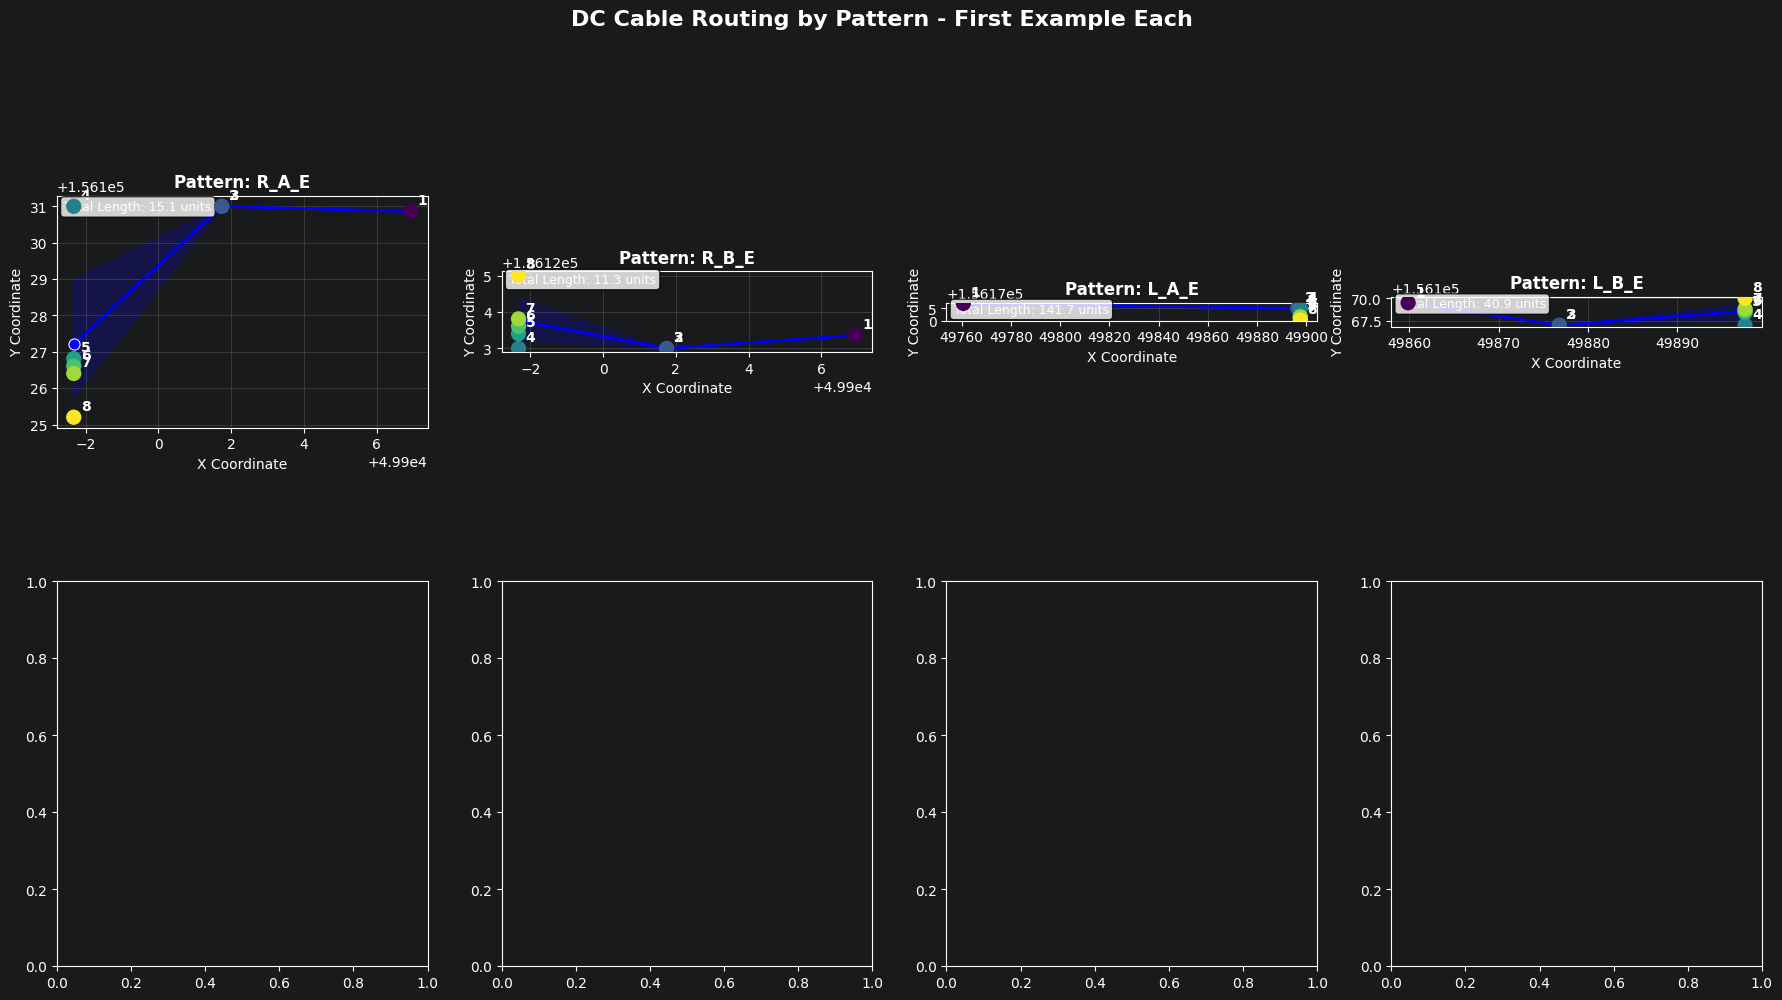

In [45]:
# Set up the figure
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
fig.suptitle('DC Cable Routing by Pattern - First Example Each', fontsize=16, fontweight='bold')

patterns = ["R_A_E", "R_B_E", "L_A_E", "L_B_E", "R_A_W", "R_B_W", "L_A_W", "L_B_W"]

for idx, pattern in enumerate(patterns):
    ax = axes[idx // 4, idx % 4]

    # Get first occurrence of this pattern
    pattern_data = cables_df[cables_df['Relative_Position'] == pattern].iloc[0]

    # Define the 8 points in order
    points_x = [
        pattern_data['X'],      # 1. End of string
        pattern_data['closest_x'],     # 2. Pile coordinates
        pattern_data['closest_x'],     # 3. Pile X and Line of Structure
        pattern_data['inverter_x'],    # 4. Inverter X and Line of Structure
        pattern_data['inverter_x'],    # 5. Intermediary for stretching
        pattern_data['inverter_x'],    # 6. Intermediary for stretching
        pattern_data['inverter_x'],    # 7. Intermediary for stretching
        pattern_data['inverter_x']     # 8. Inverter coordinates
    ]

    points_y = [
        pattern_data['Y'],           # 1. End of string
        pattern_data['Line'],               # 2. Pile coordinates
        pattern_data['Line'],               # 3. Pile X and Line of Structure
        pattern_data['Line'],               # 4. Inverter X and Line of Structure
        pattern_data['intermediary_y_1'],   # 5. Intermediary
        pattern_data['intermediary_y_2'],   # 6. Intermediary
        pattern_data['intermediary_y_3'],   # 7. Intermediary
        pattern_data['inverter_y']          # 8. Inverter
    ]

    # Create a DataFrame for this cable
    cable_df = pd.DataFrame({'X': points_x, 'Y': points_y, 'Point': range(1, 9)})

    # Plot using seaborn lineplot
    sns.lineplot(data=cable_df, x='X', y='Y', ax=ax, color='blue',
                 marker='o', markersize=8, linewidth=2)

    # Color the points differently
    scatter = ax.scatter(cable_df['X'], cable_df['Y'], c=cable_df['Point'],
                        cmap='viridis', s=100, zorder=5)

    # Add point numbers
    for _, row in cable_df.iterrows():
        ax.annotate(str(int(row['Point'])), (row['X'], row['Y']),
                   xytext=(5, 5), textcoords='offset points',
                   fontsize=10, fontweight='bold')

    ax.set_title(f'Pattern: {pattern}', fontsize=12, fontweight='bold')
    ax.set_xlabel('X Coordinate')
    ax.set_ylabel('Y Coordinate')
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

    # Add distance info
    total_length = sum(((points_x[i+1] - points_x[i])**2 +
                       (points_y[i+1] - points_y[i])**2)**0.5
                      for i in range(len(points_x)-1))
    ax.text(0.02, 0.98, f'Total Length: {total_length:.1f} units',
           transform=ax.transAxes, fontsize=9,
           verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()